In [1]:
 # pip install micrograd

In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
def f(x):
    return 3*x**2 - 4*x + 5

In [4]:
f(3.0)

20.0

In [5]:
xs = np.arange(-6,6,0.25)
xs

array([-6.  , -5.75, -5.5 , -5.25, -5.  , -4.75, -4.5 , -4.25, -4.  ,
       -3.75, -3.5 , -3.25, -3.  , -2.75, -2.5 , -2.25, -2.  , -1.75,
       -1.5 , -1.25, -1.  , -0.75, -0.5 , -0.25,  0.  ,  0.25,  0.5 ,
        0.75,  1.  ,  1.25,  1.5 ,  1.75,  2.  ,  2.25,  2.5 ,  2.75,
        3.  ,  3.25,  3.5 ,  3.75,  4.  ,  4.25,  4.5 ,  4.75,  5.  ,
        5.25,  5.5 ,  5.75])

In [6]:
ys = f(xs)
ys

array([137.    , 127.1875, 117.75  , 108.6875, 100.    ,  91.6875,
        83.75  ,  76.1875,  69.    ,  62.1875,  55.75  ,  49.6875,
        44.    ,  38.6875,  33.75  ,  29.1875,  25.    ,  21.1875,
        17.75  ,  14.6875,  12.    ,   9.6875,   7.75  ,   6.1875,
         5.    ,   4.1875,   3.75  ,   3.6875,   4.    ,   4.6875,
         5.75  ,   7.1875,   9.    ,  11.1875,  13.75  ,  16.6875,
        20.    ,  23.6875,  27.75  ,  32.1875,  37.    ,  42.1875,
        47.75  ,  53.6875,  60.    ,  66.6875,  73.75  ,  81.1875])

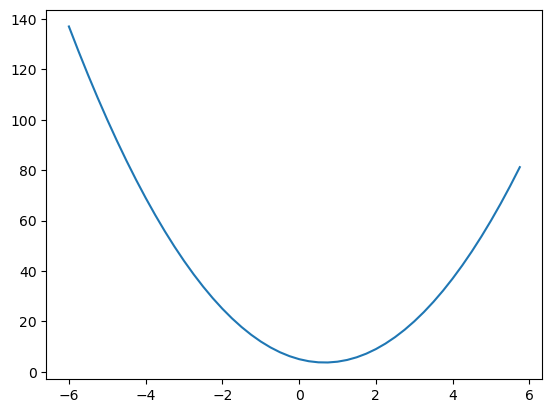

In [7]:
plt.plot(xs,ys)

In [8]:
# derivative at x=3
h = 0.000000000001
x = 3.0
(f(x+h)-f(x))/h

14.001244608152774

In [9]:
# derivative at x= -3.0
h = 0.00000001
x = 2/3
(f(x+h)-f(x))/h

0.0

In [10]:
# more complex case
a=2.0
b=-3.0
c=10.0
d=a*b+c
print(d)

4.0


In [11]:
#find the derivative of d with respect to a,b and c
h = 0.0001

# inputs 
a=2.0
b=-3.0
c=10.0
d = a*b + c

d1 = a*b + c
c += h
d2 = a*b + c

print('d1 is ', d1)
print('d2 is ', d2)
print('slope is ', (d2-d1)/h)

d1 is  4.0
d2 is  4.0001
slope is  0.9999999999976694


In [30]:
# simple value object

# the __repr__ function is helping in printing out the values properly, without it we would get hex numbers when printing
class Value:
    def __init__(self, data, _children=(), _op ='', label=''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._prev = set(_children)
        self._op = _op
        self.label = label
    def __repr__(self):
        return f"Value(data={self.data})"
    def __add__(self, other):
        out = Value(self.data + other.data, _children = (self, other), _op = '+') 
        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad

        out._backward = _backward
        return out
    def __mul__(self, other):
        out = Value(self.data * other.data, _children = (self, other), _op = '*')
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
        out = Value(t,(self, ),'tanh')
        def _backward():
            self.grad += (1 - t**2) * out.grad
        out._backward = _backward
        return out

    def backward(self):
        # made the topological list
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        self.grad = 1.0 # set the output grad to 1
        # go from the reversed order of the topological list
        for node in reversed(topo):
            node._backward()
            
        

# a = Value(2.0, label='a')
# b = Value(-3.0, label='b')
# c = Value(10.0, label='c')
# e = a*b
# e.label='e'
# d = e + c # (a.__mul__(b)).__add__(c)
# d.label='d'
# f = Value(-2.0, label='f')
# L = d*f; L.label='L'

# print(a + b) # python will call a.__add__(b)
# print(f'operation happened ={(a+b)._op}')
# print(d._prev)
# print(d._op)

In [13]:
from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges
def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})  # LR = left to right

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # for any value in the graph, create a rectangular ('record') node for it
        dot.node(name=uid, label="{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')

        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name=uid + n._op, label=n._op)
            # and connect this node to it
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

In [29]:
# draw_dot(L)

In [28]:
# # lets try to nudge our inputs by a small step (step size = 0.01) to try to make L go up
# a.data += 0.01 * a.grad
# b.data += 0.01 * b.grad
# c.data += 0.01 * c.grad
# f.data += 0.01 * f.grad

# # forward pass
# e = a * b
# d = e + c
# L = d * f

# print(L.data)

In [26]:
# # manually calculating the derivatives and gradient
# L.grad = 1.0
# d.grad = -2.0 # dL/dd = dL/dd(L * f) = f
# f.grad = 4.0 # dL/df = dL/df(L * f) = L
# c.grad = -2.0 # dL/dc = dd/dc * dL/dd
# e.grad = -2.0 # dL/de = dd/de * dL/dd
# a.grad = 6.0 # dL/da = de/da * dd/de * dL/dd
# b.grad = -4.0 # dL/db = de/db * dd/de * dL/dd

In [27]:
# def lol():
#     h = 0.001
#     a = Value(2.0, label='a')
#     b = Value(-3.0, label='b')
#     c = Value(10.0, label='c')
#     e = a*b
#     e.label='e'
#     d = e + c # (a.__mul__(b)).__add__(c)
#     d.label='d'
#     f = Value(-2.0, label='f')
#     L = d*f; L.label='L'
#     L1 = L.data

#     a = Value(2.0 , label='a')
#     # a.data += h # to get derivative of a
#     b = Value(-3.0, label='b')
#     b.data += h # to get derivative of b
#     c = Value(10.0, label='c')
#     # c.data += h # to get derivative of c
#     e = a*b
#     # e.data += h # to get derivative of e
#     e.label='e'
#     d = (e + c)
#     d.label='d'
#     # d.data += h # to get derivative of d
#     f = Value(-2.0 , label='f')
#     L = d*f; L.label='L'
#     L2 = L.data
#     print(f"Derivative of L , {(L2-L1)/h}")

# lol()

In [25]:
# plt.plot(np.arange(-5,5,0.2), np.tanh(np.arange(-5,5,0.2)))
# plt.grid()

In [19]:
#inputs x1,x2
x1 = Value(2.0, label = 'x1')
x2 = Value(0.0, label = 'x2')

#weights w1,w2
w1 = Value(-3.0, label = 'w1')
w2 = Value(1.0, label = 'w2')

# bias of the neuron
b = Value(6.8813735870195432, label = 'b')

x1w1 = x1*w1
x1w1.label='x1*w1'
x2w2 = x2*w2
x2w2.label='x2*w2'

# x1*w1 + x2*w2 + b
x1w1x2w2 = x1w1 + x2w2
x1w1x2w2.label = 'x1w1 + x2w2'
n = x1w1x2w2 + b  # n is the raw activation value without clamping the activation function on it
n.label = 'n'

o = n.tanh() #output
o.label = 'output'

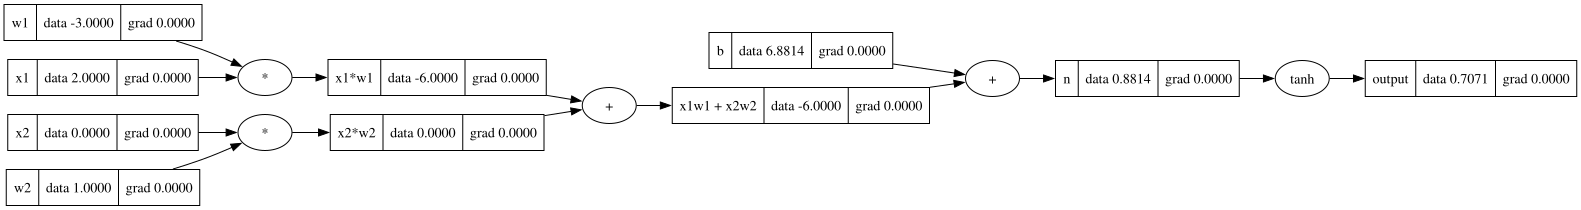

In [20]:
draw_dot(o)

In [21]:
o.backward()

In [22]:
# from here are the manual backpropagation
# gradient of x1,w1,x2,w2
# as w2 and x2 are multiplied -- each of their gradient would be the other terms data * gradient of the prev layer (x2w2)
# therefore,
x2.grad = w2.data * x2w2.grad
w2.grad = x2.data * x2w2.grad

x1.grad = w1.data * x1w1.grad
w1.grad = x1.data * x1w1.grad

# since x1w1 and x2w2 has addition, the gradient of x1w1x2w2 would flow to each of them
x1w1.grad = x1w1x2w2.grad
x2w2.grad = x1w1x2w2.grad

# since x1w1x2w2 and b has addition, the gradient of n would flow to each of them
x1w1x2w2.grad = n.grad
b.grad = n.grad

# to backpropagate through the tanh, we need to know the local derivative of tanh
# o = tanh(n)
# do/dn = 1 - tanh(n)**2 -- we already have o = tanh(n) calculated
# thus n.grad will be 1 - (o.data)**2
n.grad = 1 - (o.data)**2

# backpropagation manually
o.grad = 1.0


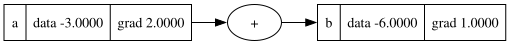

In [23]:
a = Value(-3.0, label='a')
b = a + a; b.label='b'
b.backward()
draw_dot(b)

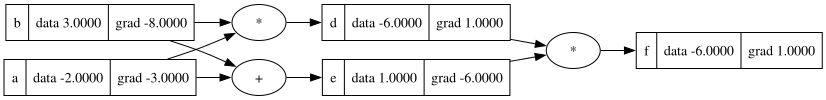

In [24]:
# multivariable chain rule / adding up or accumulating the gradients
a = Value(-2.0, label='a')
b = Value(3.0, label='b')
d = a * b; d.label='d'
e = a + b; e.label='e'
f = d * e; f.label='f'

f.backward()
draw_dot(f)